# 20 · A Shift-Aware Detector (v2), Built Without Test Labels

**The question:** Notebook 19 showed that the official test traffic differs from the training traffic, and that this shift caused most false alarms.
Can we build a detector that is **prepared for the new traffic**, using only what a real deployment would have: the new traffic's **measurements, but not
its labels**?

| | |
|---|---|
| **Input** | Training file (with labels), and the **test file's 42 measurement columns only** (labels removed at load time) |
| **What we do** | Measure the shift without labels; build candidate detectors that ignore drifting columns or re-weight training rows; choose with an estimate that needs no test labels |
| **Output** | Detector **v2** and its settings. Notebook 21 evaluates it once on the test file |

### Why this is legitimate, and what we must disclose

- A deployed detector always sees the incoming traffic before anyone labels it. Using those **unlabelled measurements** to adapt is a standard technique
  (covariate-shift adaptation). **No test label is used anywhere in this notebook.**
- Honest disclosure for the paper: the *idea* to adapt to the shift came from Notebook 19's test result. So v2 is a **post-hoc improvement**, reported
  next to the pre-registered v1, never instead of it.

## 1. Setup: the test labels are removed immediately

In [1]:
import sys
import time
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lightgbm import LGBMClassifier
from scipy import sparse
from scipy.stats import ks_2samp
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from src.notebook_helpers import TRAIN_CSV, TEST_CSV, RAW_SHA256, CLASSES, DATA, MODELS, sha256, save_table, save_figure, save_json, read_json, setup_style
from src.final_detector import Preprocessor, load_raw, source_feature
from src.flow_networks import class_weights
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train'] and sha256(TEST_CSV) == RAW_SHA256['test']

pre = Preprocessor()
raw = {r: load_raw(r) for r in ['train', 'model_selection', 'calibration']}
test_features = load_raw('test').drop(columns=['id', 'label', 'attack_cat'])          # labels dropped here, never loaded again
assert not {'label', 'attack_cat'} & set(test_features.columns)
X = {r: pre.transform(f)['tree'] for r, f in raw.items()}
X['test'] = pre.transform(test_features)['tree']
y = {r: pd.Categorical(f.attack_cat, categories=CLASSES).codes.astype(int) for r, f in raw.items()}
names = pre.columns['tree']
print({k: v.shape for k, v in X.items()})

{'train': (140273, 195), 'model_selection': (17534, 195), 'calibration': (17534, 195), 'test': (82332, 195)}


## 2. How different is the new traffic? (no labels needed)

**Adversarial validation:** we train a classifier to guess whether a flow comes from the training file or the test file, using only its measurements.
If the two files looked the same, it could not do better than guessing (AUC 0.5). The further above 0.5, the stronger the shift.
We use 5-fold out-of-fold predictions, so every row is scored by a model that did not see it.

In [2]:
train_file = sparse.vstack([X['train'], X['model_selection'], X['calibration']]).tocsr()
domain_X = sparse.vstack([train_file, X['test']]).tocsr()
domain_y = np.r_[np.zeros(train_file.shape[0]), np.ones(X['test'].shape[0])]
oof = np.zeros(len(domain_y))
for k, (a, b) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(np.zeros(len(domain_y)), domain_y)):
    m = LGBMClassifier(n_estimators=200, num_leaves=31, learning_rate=0.1, random_state=0, n_jobs=8, verbosity=-1)
    m.fit(domain_X[a], domain_y[a])
    oof[b] = m.predict_proba(domain_X[b])[:, 1]
print(f'adversarial AUC (training file vs test file): {roc_auc_score(domain_y, oof):.3f}   (0.5 = no shift)')

domain_model = LGBMClassifier(n_estimators=200, num_leaves=31, learning_rate=0.1, random_state=0, n_jobs=8, verbosity=-1).fit(domain_X, domain_y)
gain = pd.Series(domain_model.booster_.feature_importance('gain'), index=names)
by_source = (gain.groupby([source_feature(n) for n in names]).sum() / gain.sum()).sort_values(ascending=False)
ks = {f: ks_2samp(pd.concat([raw[r][f] for r in raw]).astype(float), test_features[f].astype(float)).statistic
      for f in by_source.index[:12] if f not in ('proto', 'service', 'state')}
shift = pd.DataFrame({'share of the drift signal': by_source.head(12), 'KS distance (0 = same distribution)': pd.Series(ks)})
save_table(shift, '20_shift_by_feature', index=True)
display(shift.round(3))

adversarial AUC (training file vs test file): 0.896   (0.5 = no shift)


,share of the drift signal,KS distance (0 = same distribution)
ackdat,0.0370,0.0970
ct_dst_sport_ltm,0.1130,0.0800
ct_dst_src_ltm,0.1140,0.1040
ct_src_ltm,0.0540,0.0690
ct_srv_dst,0.0550,0.0460
ct_srv_src,0.0870,0.0500
dbytes,0.0390,0.0440
dmean,0.0380,0.0440
proto,0.0360,NaN
sbytes,0.0800,0.0470


**What we see:**

- **The shift is strong:** a classifier tells training-file flows from test-file flows with **AUC 0.896**, using measurements only.
- It relies most on the **recent-flow counters** (`ct_dst_src_ltm`, `ct_dst_sport_ltm`, `ct_srv_src`, `ct_srv_dst`, `ct_src_ltm`: together about 42% of the
  drift signal), then on sizes (`sbytes`, `dbytes`, `smean`, `dmean`) and timing (`sinpkt`, `ackdat`).
- The counters are computed over recent connections, so they depend on what else was happening on the network when a flow was captured. A different
  capture period changes them even for the same kind of traffic.
- Per column the differences are moderate (KS distances 0.04-0.11); it is their **combination** that makes the two files easy to tell apart.

## 3. Importance weights: making training rows look like the new traffic

From the adversarial classifier we get, for every training-file row, how much more typical it is of the new traffic than of the old:
**weight = p(test) / p(train)** (scaled so the average weight is 1). Rows that resemble the new traffic count more.

Very large weights make estimates unstable, so weights are **capped at their 99th percentile** (fixed in advance). The *effective sample size* tells how
many equally weighted rows the weighted data is worth.

,rows,effective rows (weighted),largest weight
train,"140,273.0000","63,207.3000",6.3000
model_selection,"17,534.0000","7,858.1000",6.1000
calibration,"17,534.0000","7,892.7000",6.3000


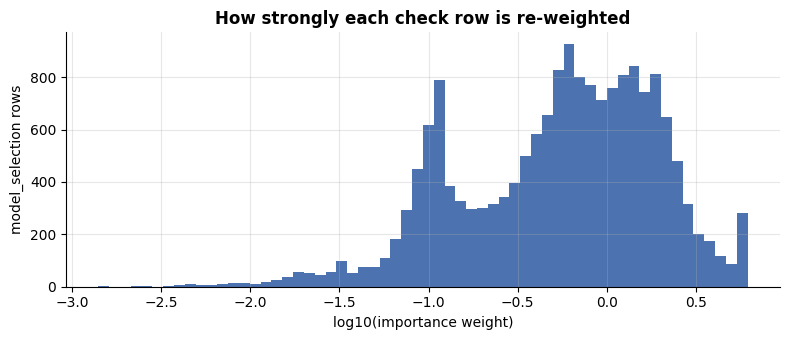

In [3]:
n_file, n_test = train_file.shape[0], X['test'].shape[0]
p_file = np.clip(oof[:n_file], 1e-6, 1 - 1e-6)
ratio = p_file / (1 - p_file) * n_file / n_test
ratio = np.minimum(ratio, np.percentile(ratio, 99))
sizes = [X[r].shape[0] for r in ['train', 'model_selection', 'calibration']]
raw_weights = dict(zip(['train', 'model_selection', 'calibration'], np.split(ratio, np.cumsum(sizes)[:-1])))
weights = {r: w / w.mean() for r, w in raw_weights.items()}          # mean 1 per role (for training and the IW estimate)
p_test = np.clip(oof[n_file:], 1e-6, 1 - 1e-6)
test_ratio = np.minimum(p_test / (1 - p_test) * n_file / n_test, np.percentile(ratio, 99))

ess = pd.DataFrame({r: {'rows': len(w), 'effective rows (weighted)': w.sum() ** 2 / (w ** 2).sum(), 'largest weight': w.max()} for r, w in weights.items()}).T
display(ess.round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(weights['model_selection']), bins=60, color='#4C72B0')
ax.set(xlabel='log10(importance weight)', ylabel='model_selection rows', title='How strongly each check row is re-weighted')
plt.tight_layout(); save_figure(fig, '20_importance_weights'); plt.show()

## 4. Estimating test performance without test labels

A **weighted** macro F1 on the `model_selection` rows (each row counts with its importance weight) estimates how a model would score on traffic that
looks like the new file. This **importance-weighted (IW) macro F1** is our selection score in this notebook. It needs no test labels.

It rests on one assumption: for a given measurement pattern, the chance of each class is the same in both files (only *which* patterns occur changes).
Notebook 21 shows how well this estimate worked.

In [4]:
def iw_macro_f1(y_true, pred, w):
    return f1_score(y_true, pred, average='macro', labels=range(10), sample_weight=w, zero_division=0)


def make_lgbm(num_leaves=31, n_estimators=120, learning_rate=0.1):
    return LGBMClassifier(objective='multiclass', n_estimators=n_estimators, learning_rate=learning_rate, num_leaves=num_leaves, reg_lambda=1.0,
                          min_child_samples=20, random_state=42, n_jobs=8, deterministic=True, force_col_wise=True, verbosity=-1)

## 5. The candidates (fixed before training)

| Dropped columns | Why |
|---|---|
| none | the v1 detector design |
| TTL group: `sttl`, `dttl`, `ct_state_ttl` | the strongest feature, flagged as testbed-specific in Notebooks 03, 16 and 19 |
| recent-flow counters: `ct_srv_src`, `ct_srv_dst`, `ct_dst_ltm`, `ct_src_ltm`, `ct_src_dport_ltm`, `ct_dst_sport_ltm`, `ct_dst_src_ltm` | the biggest share of the drift signal above |
| both groups | remove both sources of shift |

Each is trained **with and without importance weights** (always with the sqrt class weights of Notebook 10): 8 candidates.

In [5]:
TTL = ['sttl', 'dttl', 'ct_state_ttl']
COUNTERS = ['ct_srv_src', 'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm']
GROUPS = {'all columns': [], 'without TTL': TTL, 'without counters': COUNTERS, 'without TTL and counters': TTL + COUNTERS}
class_w = class_weights(y['train'], 'sqrt')
y_ms, w_ms = y['model_selection'], weights['model_selection']

candidates, fitted = [], {}
for group, dropped in GROUPS.items():
    keep = [i for i, n in enumerate(names) if source_feature(n) not in set(dropped)]
    for weighted in (False, True):
        start = time.time()
        sample_w = class_w[y['train']] * (weights['train'] if weighted else 1.0)
        model = make_lgbm().fit(X['train'][:, keep], y['train'], sample_weight=sample_w)
        pred = model.predict(X['model_selection'][:, keep])
        name = f"{group}{' + importance weights' if weighted else ''}"
        fitted[name] = (model, keep, dropped)
        candidates.append({'candidate': name, 'dropped columns': len(dropped), 'importance-weighted training': weighted,
                           'macro F1 (model_selection)': f1_score(y_ms, pred, average='macro', labels=range(10), zero_division=0),
                           'IW macro F1 (estimate for new traffic)': iw_macro_f1(y_ms, pred, w_ms),
                           'seconds': round(time.time() - start)})
        print(f"{name:45s} macro F1 {candidates[-1]['macro F1 (model_selection)']:.4f} | IW estimate {candidates[-1]['IW macro F1 (estimate for new traffic)']:.4f}")
candidates = pd.DataFrame(candidates).set_index('candidate')
save_table(candidates, '20_candidates', index=True)
display(candidates.round(4))
BEST = candidates['IW macro F1 (estimate for new traffic)'].idxmax()
print('Chosen by the IW estimate:', BEST)

all columns                                   macro F1 0.6662 | IW estimate 0.7043


all columns + importance weights              macro F1 0.6596 | IW estimate 0.7050


without TTL                                   macro F1 0.6503 | IW estimate 0.6929


without TTL + importance weights              macro F1 0.6503 | IW estimate 0.6925


without counters                              macro F1 0.6107 | IW estimate 0.6408


without counters + importance weights         macro F1 0.5842 | IW estimate 0.6185


without TTL and counters                      macro F1 0.6021 | IW estimate 0.6347


without TTL and counters + importance weights macro F1 0.5818 | IW estimate 0.6113


,dropped columns,importance-weighted training,macro F1 (model_selection),IW macro F1 (estimate for new traffic),seconds
candidate,,,,,
all columns,0,False,0.6662,0.7043,6
all columns + importance weights,0,True,0.6596,0.7050,6
without TTL,3,False,0.6503,0.6929,6
without TTL + importance weights,3,True,0.6503,0.6925,6
without counters,7,False,0.6107,0.6408,5
without counters + importance weights,7,True,0.5842,0.6185,6
without TTL and counters,10,False,0.6021,0.6347,5
without TTL and counters + importance weights,10,True,0.5818,0.6113,5


Chosen by the IW estimate: all columns + importance weights


**What we see:**

- **Removing columns hurts on both scores.** Without TTL: 0.650 (estimate 0.693); without counters: 0.611 (0.641); without both: 0.602 (0.635). These
  columns carry real attack information, so dropping them costs more than it gains, according to the label-free estimate.
- **Importance weighting changes little** on its own (estimate 0.705 vs 0.704 with all columns). It is chosen by the rule, by a very small margin.
- The estimate (about 0.70) is much higher than the macro F1 v1 actually reached on the test file (0.52, Notebook 19). It assumes that a measurement
  pattern means the same class in both files; Notebook 19 found Normal flows in the test file that look like training-file attacks, which breaks that
  assumption. So the estimate is useful for **ranking** candidates (Notebook 21 checks this), not as a forecast of the actual score.
- The tuning adds a little: 400 smaller steps (learning rate 0.05) instead of 120 steps give 0.706, and larger trees (63 leaves) are worse.

## 6. A small, fair tuning of the chosen candidate

The v1 LightGBM used fixed settings. We try 4 settings (tree size × number of trees) and keep the best by the same IW estimate.

In [6]:
_, keep, dropped = fitted[BEST]
weighted = 'importance weights' in BEST
sample_w = class_w[y['train']] * (weights['train'] if weighted else 1.0)
tuning = []
for leaves in (31, 63):
    for trees, lr in ((120, 0.1), (400, 0.05)):
        model = make_lgbm(leaves, trees, lr).fit(X['train'][:, keep], y['train'], sample_weight=sample_w)
        pred = model.predict(X['model_selection'][:, keep])
        tuning.append({'num_leaves': leaves, 'trees': trees, 'learning rate': lr, 'model': model,
                       'macro F1 (model_selection)': f1_score(y_ms, pred, average='macro', labels=range(10), zero_division=0),
                       'IW macro F1': iw_macro_f1(y_ms, pred, w_ms)})
tuning = pd.DataFrame(tuning)
save_table(tuning.drop(columns='model'), '20_tuning')
display(tuning.drop(columns='model').round(4))
best_row = tuning.loc[tuning['IW macro F1'].idxmax()]
model = best_row.model
print('chosen settings:', {k: best_row[k] for k in ['num_leaves', 'trees', 'learning rate']})

,num_leaves,trees,learning rate,macro F1 (model_selection),IW macro F1
0,31,120,0.1000,0.6596,0.7050
1,31,400,0.0500,0.6630,0.7060
2,63,120,0.1000,0.6490,0.6904
3,63,400,0.0500,0.6469,0.6955


chosen settings: {'num_leaves': np.int64(31), 'trees': np.int64(400), 'learning rate': np.float64(0.05)}


## 7. Correcting for different class shares (label shift)

The new traffic may also contain a **different mix of classes** (for example more Normal flows). **Black-box shift estimation** estimates the new class
shares without labels: it compares how often the model *predicts* each class on the new traffic with how often it predicts each class for each true
class on labelled rows (the `calibration` rows). The model's probabilities are then multiplied by (new share / old share).
The correction is kept only if it improves the IW estimate (rule fixed in advance).

In [7]:
pred_cal = model.predict(X['calibration'][:, keep])
confusion = np.zeros((10, 10))                                         # P(predicted = i, true = j) on the calibration rows
np.add.at(confusion, (pred_cal, y['calibration']), 1)
confusion /= confusion.sum()
predicted_share_new = np.bincount(model.predict(X['test'][:, keep]), minlength=10) / X['test'].shape[0]
new_share, *_ = np.linalg.lstsq(confusion, predicted_share_new, rcond=None)
new_share = np.clip(new_share, 1e-4, None); new_share /= new_share.sum()
old_share = np.bincount(y['train'], minlength=10) / len(y['train'])
prior_ratio = new_share / old_share
display(pd.DataFrame({'share in training rows': old_share, 'estimated share in new traffic': new_share, 'correction factor': prior_ratio},
                     index=CLASSES).round(4))

p_ms = model.predict_proba(X['model_selection'][:, keep])
p_adj = p_ms * prior_ratio; p_adj /= p_adj.sum(axis=1, keepdims=True)
without, with_ = iw_macro_f1(y_ms, p_ms.argmax(1), w_ms), iw_macro_f1(y_ms, p_adj.argmax(1), w_ms)
USE_PRIOR = bool(with_ > without)
print(f'IW macro F1 without correction {without:.4f} | with correction {with_:.4f} -> correction kept: {USE_PRIOR}')

,share in training rows,estimated share in new traffic,correction factor
Analysis,0.0114,0.1988,17.4331
Backdoor,0.0100,0.6238,62.6313
DoS,0.0699,0.0000,0.0000
Exploits,0.1904,0.0314,0.1650
Fuzzers,0.1037,0.0378,0.3647
Generic,0.2281,0.0256,0.1121
Normal,0.3194,0.0275,0.0861
Reconnaissance,0.0598,0.0149,0.2487
Shellcode,0.0065,0.0402,6.2156
Worms,0.0007,0.0000,0.0035


IW macro F1 without correction 0.7060 | with correction 0.5656 -> correction kept: False


**What we see:**

- The estimated class shares of the new traffic are **not plausible** (for example 62% Backdoor and 2.7% Normal). The method assumes that only the class
  mix changes, while each class looks the same; here the flows themselves change, and the strongly conflicting classes (Analysis, Backdoor, DoS) make the
  estimate unstable.
- The rule fixed in advance catches this: the correction lowers the estimate (0.706 → 0.566), so it is **not used**.

## 8. Detector v2

The chosen candidate, settings and correction together form **detector v2**. We also save everything Notebook 21 needs for **weighted conformal
prediction**: the importance weights of the calibration rows and of the new traffic.

In [8]:
joblib.dump(model, MODELS / '20_detector_v2_lightgbm.joblib')
spec = {'detector': 'lightgbm', 'name': f'LightGBM v2 ({BEST})', 'lightgbm_model': 'models/v3/20_detector_v2_lightgbm.joblib',
        'lightgbm_treatment': 'sqrt', 'dropped_features': list(dropped), 'importance_weighted_training': weighted,
        'settings': {k: (best_row[k].item() if hasattr(best_row[k], 'item') else best_row[k]) for k in ['num_leaves', 'trees', 'learning rate']},
        'prior_ratio': prior_ratio.tolist() if USE_PRIOR else None,
        'iw_macro_f1_estimate': float(with_ if USE_PRIOR else without), 'test_labels_used': False}
save_json(spec, MODELS / 'final_detector_v2.json')
# Weighted conformal needs the same (unnormalised) scale for calibration rows and new flows.
np.savez_compressed(DATA / '20_importance_weights.npz', calibration=raw_weights['calibration'], model_selection=raw_weights['model_selection'], test=test_ratio)
for name_, (m, k, d) in fitted.items():                                 # every candidate, so Notebook 21 can show how well the selection worked
    joblib.dump((m, k, d), MODELS / f"20_candidate_{name_.replace(' ', '_').replace('+', 'plus')}.joblib")
display(pd.Series(spec).to_frame('detector v2'))
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

,detector v2
detector,lightgbm
name,LightGBM v2 (all columns + importance weights)
lightgbm_model,models/v3/20_detector_v2_lightgbm.joblib
lightgbm_treatment,sqrt
dropped_features,[]
importance_weighted_training,True
settings,"{'num_leaves': 31, 'trees': 400, 'learning rat..."
prior_ratio,None
iw_macro_f1_estimate,0.7060
test_labels_used,False


## Summary

### What we did

| Step | Result |
|---|---|
| Measure the shift (no labels) | Strong: AUC 0.896; mostly the recent-flow counters, then sizes and timing |
| Importance weights | Capped at the 99th percentile; about 45% effective sample size |
| 8 candidates (drop TTL / counters / both, with or without weights) | Dropping columns lowers the estimate; all columns + importance weights is chosen (by a very small margin) |
| Tuning | 400 trees with learning rate 0.05 (estimate 0.706) |
| Class-share correction | Rejected by the rule (implausible estimates, lower score) |
| **Detector v2** | **LightGBM, all columns, sqrt class weights × importance weights, 400 trees**; no test labels used |

### What is still uncertain

- The importance-weighted estimate assumes that the meaning of a measurement pattern does not change between files. Notebook 19 suggests it partly does,
  so the estimate cannot predict the real test score, only (perhaps) the ranking of candidates.

### What comes next

**Notebook 21** evaluates v2 once on the test file, compares it with v1, tests weighted conformal sets, and checks how well the label-free selection worked.